<a href="https://colab.research.google.com/github/MyMed1000/IAODC_Mohammed/blob/main/Untitled31.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install nltk

In [3]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [8]:
def deep_model(model, X_train, y_train, X_valid, y_valid):
  model.compile(optimizer='rmsprop' ,
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  history = model.fit(X_train,
                      y_train,
                      epochs=NB_START_EPOCHS,
                      batch_size=BATCH_SIZE,
                      validation_data=(X_valid, y_valid),
                      verbose=0)
  return history


In [9]:
import matplotlib.pyplot as plt
def eval_metric(model, history, metric_name):

  metric = history.history[metric_name]
  val_metric = history.history['val_' + metric_name]

  e = range(1, NB_START_EPOCHS + 1)

  plt.plot(e, metric, 'bo', label='Apprentissage' + metric_name)
  plt.plot(e, val_metric, 'b', label='Validation' + metric_name)
  plt.xlabel('Epoch number')
  plt.ylabel(metric_name)
  plt.title('Comparaison entre apprentissage et validatin' + metric_name + 'for' + model.name)
  plt.legend()
  plt.show()


In [11]:
def test_model(model, X_train, y_train, X_test, y_test, epoch_stop):
  model.fit(X_train,
            y_train,
            epochs=epochs_stop,
            batch_size=BATCH_SIZE,
            verbose=0)
  results = model.evaluate(X_test, y_test)
  print()
  print('Test accuracy:{0:.2f}%'.format(results[1]*100))
  return results

In [21]:
def compare_models_by_metric(model_1, model_2, model_hist_1, model_hist_2, metric):
  metric_model_1 = model_hist_1.history[metric]
  metric_model_2 = model_hist_2.history[metric]

  e = range(1, NB_START_EPOCHS + 1)
  metric_dict = {
      'acc' : 'Accuracy Apprentissage',
      'loss' : 'Loss Apprentissage',
      'val_acc' : 'Accuracy Validation',
      'val_loss' : 'Loss Validation'
  }

  metric_label = metric_dict[metric]
  plt.plot(e, metric_model_1, 'ro', label=model_1.name)
  plt.plot(e, metric_model_2, 'r', label=model_2.name)
  plt.xlabel('Nombre Epoques')
  plt.ylabel(metric_label)
  plt.title('Comparaison de ' + metric_label + ' entre les modèles')
  plt.legend()
  plt.show()

In [23]:
def optimal_epoch(model_hist):
  min_epoch = np.argmin(model_hist.history['val_loss']) + 1
  print("Perte de validation minimale attenite à l'époque {}".format(min_epoch))
  return min_epoch

In [24]:
import nltk
from nltk.corpus import stopwords
def remove_stopwords(iput_text):
  stopwords_list = stopwords.words('english')
  whitelist = ["n't," "not", "no"]
  words = input_text.split()
  clean_words = [word for word in words if (word not in stopwords_list or word in whitelist)and len(word)> 1]
  return " ".join(clean_words)

In [25]:
import re
def remove_mentions(input_text):
  return re.sub(r'@\w+', '', input_text)

In [27]:
import pandas as pd
df = pd.read_csv('/content/Tweets.csv')

In [28]:
df

,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative
...,...,...,...,...
27476,4eac33d1c0,wish we could come see u on Denver husband l...,d lost,negative
27477,4f4c4fc327,I`ve wondered about rake to. The client has ...,", don`t force",negative
27478,f67aae2310,Yay good for both of you. Enjoy the break - y...,Yay good for both of you.,positive
27479,ed167662a5,But it was worth it ****.,But it was worth it ****.,positive


In [30]:
import numpy as np
df = df.reindex(np.random.permutation(df.index))

In [32]:
df = df[['text', 'sentiment']]

In [35]:
df = df.dropna(subset=['text', 'sentiment'])

In [36]:
df.head()

,text,sentiment
8258,Next movies for me : Terminator Salvation and ...,neutral
19664,Spent some time exploring Atlas and Hercules c...,neutral
13441,stranded @ delhi Airport flight delayed,negative
22736,OMG..5 days till 1st state exam!,neutral
22319,On my shoot with Ron and Torey! Have lots of fun,positive


In [38]:
import re
stop_words = set(stopwords.words('english'))

def nettoyer_texte(texte):
    texte = texte.lower()
    texte = re.sub(r'@\w+', '', texte)
    texte = re.sub(r'http\S+|www\.\S+', '', texte)
    texte = re.sub(r'[^a-z\s]', '', texte)
    mots = texte.split()
    mots = [mot for mot in mots if mot not in stop_words]

    return ' '.join(mots)

df['text'] = df['text'].apply(nettoyer_texte)

print(df[['text', 'sentiment']].head())

                                                    text sentiment
8258   next movies terminator salvation transformers ...   neutral
19664  spent time exploring atlas hercules craters re...   neutral
13441              stranded delhi airport flight delayed  negative
22736                        omg days till st state exam   neutral
22319                           shoot ron torey lots fun  positive


In [43]:
from sklearn.model_selection import train_test_split

X = df['text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

In [44]:
print(X_train)

9437     im looking warblers seen yellow far blue grey ...
6598                                    sturday night live
9919     looking forward seeing relatives maybe home to...
10049    justin timberlake leonard nimoy box sequel pri...
19822                     really nice smoothy baulko shops
                               ...                        
26498                                       happy moms day
20757    soo happy today going home bit sucks meeting e...
2492                                            lurveeeeee
15718           tea found picture big snail walk yesterday
18959                          surprises unfortunately yes
Name: text, Length: 24732, dtype: object


In [45]:
print(y_train)

9437      neutral
6598      neutral
9919      neutral
10049    positive
19822    positive
           ...   
26498    positive
20757     neutral
2492     positive
15718     neutral
18959    negative
Name: sentiment, Length: 24732, dtype: object


In [47]:
from tensorflow.keras.preprocessing.text import Tokenizer
import collections

NB_WORDS = 10000

tk = Tokenizer(num_words=NB_WORDS,
               filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n',
               lower=True,
               char_level=False,
               split=' ')

tk.fit_on_texts(X_train)

print('Ajustement du tokenizer sur {} documents'.format(tk.document_count))
print('{} mots du dictionnaire'.format(tk.num_words))
print('Top 5 mots les plus courants :', collections.Counter(tk.word_counts).most_common(5))
print(list(tk.word_index.items())[:10])

Ajustement du tokenizer sur 24732 documents
10000 mots du dictionnaire
Top 5 mots les plus courants : [('im', 2726), ('day', 1869), ('good', 1367), ('get', 1288), ('like', 1221)]
[('im', 1), ('day', 2), ('good', 3), ('get', 4), ('like', 5), ('go', 6), ('dont', 7), ('work', 8), ('love', 9), ('today', 10)]


In [49]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

y_categorical = to_categorical(y_encoded, num_classes=3)

print("Classes :", encoder.classes_)
print("Exemple encodé :", y_encoded[:5])
print("Exemple one-hot :", y_categorical[:5])

Classes : ['negative' 'neutral' 'positive']
Exemple encodé : [1 1 0 1 2]
Exemple one-hot : [[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

X_train_matrix = tk.texts_to_matrix(X_train, mode='binary')
X_test_matrix = tk.texts_to_matrix(X_test, mode='binary')

encoder = LabelEncoder()
encoder.fit(y_train)

y_train_encoded = encoder.transform(y_train)
y_test_encoded = encoder.transform(y_test)

y_train_cat = to_categorical(y_train_encoded, num_classes=3)
y_test_cat = to_categorical(y_test_encoded, num_classes=3)

X_apprentissage, X_validation, y_apprentissage, y_validation = (
    train_test_split(
        X_train_matrix,
        y_train_cat,
        test_size=0.10,
        random_state=42,
        stratify=y_train_encoded
    )
)

print("Apprentissage :", X_apprentissage.shape)
print("Validation :", X_validation.shape)
print("Test :", X_test_matrix.shape)

Apprentissage : (22258, 10000)
Validation : (2474, 10000)
Test : (2748, 10000)


In [54]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation='relu', input_shape=(10000,)),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,419 (2.46 MB)

 Trainable params: 644,419 (2.46 MB)

 Non-trainable params: 0 (0.00 B)

In [55]:
import matplotlib.pyplot as plt

history = model.fit(
    X_apprentissage,
    y_apprentissage,
    epochs=20,
    batch_size=32,
    validation_data=(X_validation, y_validation),
    verbose=1
)

# Évaluer sur les données de test
loss_test, accuracy_test = model.evaluate(
    X_test_matrix,
    y_test_cat,
    verbose=0
)

print("Loss sur le test :", loss_test)
print("Accuracy sur le test :", accuracy_test)

Epoch 1/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.6469 - loss: 0.8060 - val_accuracy: 0.7134 - val_loss: 0.7039
Epoch 2/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7920 - loss: 0.5296 - val_accuracy: 0.6948 - val_loss: 0.7558
Epoch 3/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8753 - loss: 0.3397 - val_accuracy: 0.6884 - val_loss: 0.9226
Epoch 4/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9326 - loss: 0.1978 - val_accuracy: 0.6863 - val_loss: 1.1215
Epoch 5/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.9650 - loss: 0.1118 - val_accuracy: 0.6734 - val_loss: 1.4278
Epoch 6/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9787 - loss: 0.0695 - val_accuracy: 0.6633 - val_loss: 1.6448
Epoch 7/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9869 - loss: 0.0470 - val_accuracy: 0.6661 - val_loss: 1.9418
Epoch 8/20
696/696 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9898 - loss: 0.0353 - val_

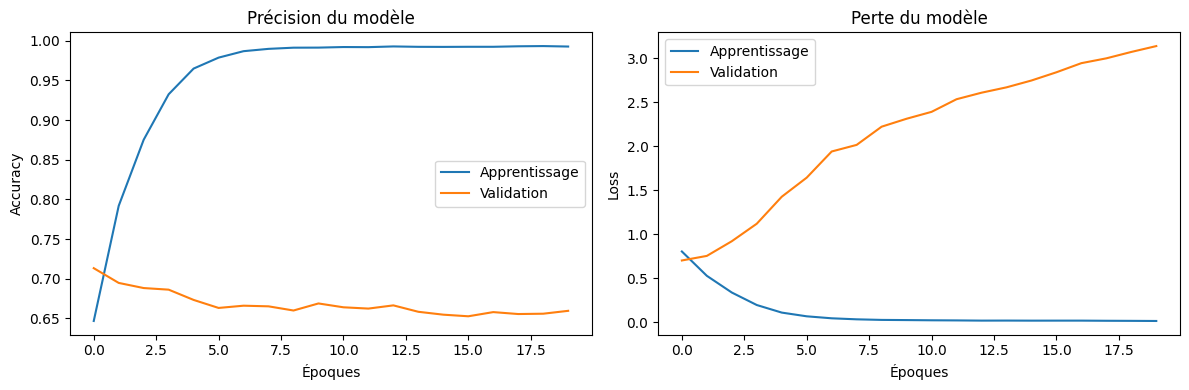

In [56]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Apprentissage')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Précision du modèle')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Apprentissage')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Perte du modèle')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()